In [1]:
import os
import sys
import glob

import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D

sys.path.insert(0, '../../..')
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.constants import Configs

GROUP_ARRAY = ['x', 'y', 'z']
TARGET_MOVEMENT = 'Move'

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


## Import Data

In [2]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [4]:
# HELPER FUNCTIONS 

def get_model_from_path(model_path):
    model_dict = {
        'dbscanFeatureExtraction': 'DBSCAN Feature Extraction',
        'LofDtw': 'Local Outlier Factor DTW',
    }

    # Extract model name from path
    file_name = os.path.basename(model_path).split('.')[0]
    file_name_array = file_name.split('_')
    for key in model_dict.keys():
        if key in file_name_array:
            return model_dict[key]
    return 'Unknown Model'

def get_movement_from_path(model_path):
    # Extract model name from path
    file_name = os.path.basename(model_path).split('.')[0]
    file_name_array = file_name.split('_')
    for key in ['Pick', 'Move', 'Place']:
        if key in file_name_array:
            return key
    return 'Unknown Movement'

# What if I show the two models outleirs in a graph, with the common ones represented in a diferent color?

First I extract all the time series from the dataset and see how many times they were detected as outliers.

In [5]:
winner_model_dict = {
        'dbscanFeatureExtraction': 'DBSCAN Feature Extraction',
        'LofDtw': 'LOF DTW',
}

def extract_outliers_from_cache(movement_type, cache_dir='../../cache/models'):
    files = glob.glob(os.path.join(cache_dir, '*.pkl'))
    movement_type_files = [f for f in files if movement_type in f]

    # Filter files to include only those from the winner models
    movement_type_files = [f for f in movement_type_files if any(model in f for model in winner_model_dict.keys())]

    # Use a dict to accumulate counts to avoid MultiIndex lexsort warnings and repeated .loc writes
    counts = {}  # key: (sub, repID, movID) -> {'movement_type': ..., 'times_detected_as_outlier': ...}

    for file in movement_type_files:
        outliers_df = joblib.load(file)
        for o in outliers_df.itertuples():
            key = (o.sub, o.repID, o.movID)
            # key = (o.sub, o.repID)
            if key not in counts:
                counts[key] = {
                    'sub': o.sub,
                    'repID': o.repID,
                    'movID': o.movID,
                    'movement_type': movement_type,
                    'model_type': get_model_from_path(file)
                }

    # Build DataFrame from the dict and create a proper MultiIndex
    detected_outlers_df = pd.DataFrame.from_dict(counts, orient='index')
    detected_outlers_df.index = pd.MultiIndex.from_tuples(detected_outlers_df.index, names=['sub', 'repID', 'movID'])

    return detected_outlers_df

all_detected_outliers_df = pd.DataFrame()
for movement in ['Pick', 'Move', 'Place']:
    for model in ['dtw', 'feature_extraction']:
        detected_outlers_df = extract_outliers_from_cache(movement, cache_dir='../../cache/models/' + model)
        all_detected_outliers_df = pd.concat([all_detected_outliers_df, detected_outlers_df], ignore_index=True)

all_detected_outliers_df.head()

""


In [ ]:
# Separate the detected outliers by model type for easier analysis
lof_outliers_df = all_detected_outliers_df[all_detected_outliers_df['model_type'] == 'Local Outlier Factor DTW']
dbscan_outliers_df = all_detected_outliers_df[all_detected_outliers_df['model_type'] == 'DBSCAN Feature Extraction']

KeyError: 'model_type'

In [ ]:
# Merge the detected outliers with the original data to get the full context for analysis
lof_outlier_data_df = pd.merge(lof_outliers_df, df, on=['sub', 'repID', 'movID'], how='left')
dbscan_outliers_df = pd.merge(dbscan_outliers_df, df, on=['sub', 'repID', 'movID'], how='left')

# Find common outliers - keep only identifier columns to avoid duplicate column suffixes
common_outliers_df = pd.merge(
    lof_outliers_df, 
    dbscan_outliers_df, 
    on=['sub', 'repID', 'movID'], 
    how='inner'
)
common_outliers_df.drop(columns=['movement_type_x', 'model_type_x', 'movement_type_y', 'model_type_y'], inplace=True)

In [ ]:
# Remove the Common outliers from the lof and dbscan dataframes to avoid duplication in the plots
lof_outlier_data_df = lof_outlier_data_df[~lof_outlier_data_df.set_index(['sub', 'repID', 'movID']).index.isin(common_outliers_df.set_index(['sub', 'repID', 'movID']).index)]
dbscan_outliers_df = dbscan_outliers_df[~dbscan_outliers_df.set_index(['sub', 'repID', 'movID']).index.isin(common_outliers_df.set_index(['sub', 'repID', 'movID']).index)]

In [ ]:
common_outliers_df[common_outliers_df['movLabel'] == "Pick"].head(15)

,sub,repID,movID,movType,step,movLabel,x,y,z,vel,acc,t,k,jerk
0,3,4,5,0,1,Pick,-538.691469,284.890270,1135.431433,0.045394,2.962648,263.107129,1343.956894,0.000000
1,3,4,5,0,2,Pick,-537.872281,285.797698,1135.360569,0.062160,3.097571,140.482384,640.501840,0.134923
2,3,4,5,0,3,Pick,-536.938594,286.307846,1134.512165,0.100315,3.276337,18.423190,201.413680,0.178766
3,3,4,5,0,4,Pick,-535.770742,286.340314,1132.931722,0.146254,3.458280,-41.843961,86.693875,0.181943
4,3,4,5,0,5,Pick,-534.249056,285.814699,1130.664740,0.197164,3.667672,-66.730580,44.956442,0.209392
5,3,4,5,0,6,Pick,-532.253869,284.650600,1127.756719,0.253486,3.948199,-74.349119,25.767679,0.280527
6,3,4,5,0,7,Pick,-529.684156,282.735468,1124.271145,0.316495,4.326105,-68.324878,16.107450,0.377907
7,3,4,5,0,8,Pick,-526.452238,279.983215,1120.235967,0.387274,4.786240,-52.231353,11.028861,0.460135
8,3,4,5,0,9,Pick,-522.357416,276.367188,1115.698626,0.466294,5.284339,-34.838747,8.079536,0.498098
9,3,4,5,0,10,Pick,-517.183501,271.886400,1110.682695,0.553520,5.781495,-21.398931,6.098227,0.497156


In [ ]:
df_full = df[df['movLabel'] == TARGET_MOVEMENT].copy()
X_lof = all_detected_outliers_df[all_detected_outliers_df['model_type'] == 'Local Outlier Factor DTW']
X_dbscan = all_detected_outliers_df[all_detected_outliers_df['model_type'] == 'DBSCAN Feature Extraction']

# Create metadata DataFrames for the full dataset and the detected outliers
full_metadata_df = (
    df_full[['sub', 'repID', 'movID']]
    .drop_duplicates()
    .reset_index(drop=True)
)
lof_model_metadata_df = (
    lof_outlier_data_df[lof_outlier_data_df['movLabel'] == TARGET_MOVEMENT][['sub', 'repID', 'movID']]
    .drop_duplicates()
    .reset_index(drop=True)
)
dbscan_model_metadata_df = (
    dbscan_outliers_df[dbscan_outliers_df['movLabel'] == TARGET_MOVEMENT][['sub', 'repID', 'movID']]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Find the indices of the detected outliers in the full dataset for both models
lof_outlier_indices = np.where(
    lof_model_metadata_df[['sub', 'repID', 'movID']].apply(tuple, axis=1).isin(
        full_metadata_df[['sub', 'repID', 'movID']].apply(tuple, axis=1)
    )
)[0]

dbscan_outlier_indices = np.where(
    dbscan_model_metadata_df[['sub', 'repID', 'movID']].apply(tuple, axis=1).isin(
        full_metadata_df[['sub', 'repID', 'movID']].apply(tuple, axis=1)
    )
)[0]

In [ ]:
X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=GROUP_ARRAY,
        sample_size=None
)  # shape (n_samples, T, n_features)

Processing time series:   0%|          | 0/95 [00:00<?, ?it/s]

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 2642.32it/s]

Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


In [ ]:
def plot_movement_analysis(
    X_movement,
    full_metadata_df,      # metadata de TODOS os samples de X_movement
    model_metadata_df,     # metadata dos outliers do modelo
    outliers_csv,          # known outliers (sub, repID)
    model_name='',
    axis_names=['x', 'y', 'z'],
    target_movement='Place'
):
    # 1) Garantir mesmas chaves
    full_keys = full_metadata_df[['sub', 'repID']].drop_duplicates().copy()
    model_keys = model_metadata_df[['sub', 'repID']].drop_duplicates().copy()
    csv_keys = outliers_csv[['sub', 'repID']].drop_duplicates().copy()

    # 2) Interseções/diferenças
    common_keys = model_keys.merge(csv_keys, on=['sub', 'repID'], how='inner')

    model_only_keys = model_keys.merge(
        csv_keys, on=['sub', 'repID'], how='left', indicator=True
    )
    model_only_keys = model_only_keys[model_only_keys['_merge'] == 'left_only'][['sub', 'repID']]

    csv_only_keys = csv_keys.merge(
        model_keys, on=['sub', 'repID'], how='left', indicator=True
    )
    csv_only_keys = csv_only_keys[csv_only_keys['_merge'] == 'left_only'][['sub', 'repID']]

    # 3) Converter keys -> índices no X_movement usando FULL metadata
    full_pairs = full_metadata_df[['sub', 'repID']].apply(tuple, axis=1)

    common_idx = np.where(full_pairs.isin(common_keys.apply(tuple, axis=1)))[0]
    model_only_idx = np.where(full_pairs.isin(model_only_keys.apply(tuple, axis=1)))[0]
    csv_only_idx = np.where(full_pairs.isin(csv_only_keys.apply(tuple, axis=1)))[0]

    X_common = X_movement[common_idx] if len(common_idx) else np.empty((0,))
    X_model_only = X_movement[model_only_idx] if len(model_only_idx) else np.empty((0,))
    X_csv_only = X_movement[csv_only_idx] if len(csv_only_idx) else np.empty((0,))

    print(f"Common: {len(common_idx)} | Model-only: {len(model_only_idx)} | CSV-only: {len(csv_only_idx)}")

    # 4) Plot
    fig, axs = plt.subplots(1, len(axis_names), figsize=(18, 6))
    if len(axis_names) == 1:
        axs = [axs]

    legend_elements = [
        Line2D([0], [0], color='red', lw=2, alpha=0.9, label='Model Only'),
        Line2D([0], [0], color='orange', lw=2, alpha=0.9, label='CSV Only'),
        Line2D([0], [0], color='blue', lw=2, alpha=0.9, label='Common'),
    ]

    for i, axis in enumerate(axis_names):
        ax = axs[i]

        for series in X_model_only:
            ax.plot(series[:, i], color='red', alpha=0.8, linewidth=2)

        for series in X_csv_only:
            ax.plot(series[:, i], color='orange', alpha=0.8, linewidth=2)

        for series in X_common:
            ax.plot(series[:, i], color='blue', alpha=0.8, linewidth=2)

        ax.set_title(f'{axis.capitalize()} Axis')
        ax.set_xlabel('Step')
        ax.set_ylabel(f'Coordinate {axis}')
        ax.grid(True, linestyle=':', alpha=0.6)

        if i == len(axis_names) - 1:
            ax.legend(handles=legend_elements, loc='upper right')

    plt.suptitle(f'Movement Analysis ({target_movement}): {model_name} Outlier Comparison', fontsize=16)
    plt.tight_layout()
    plt.show()

Common: 4 | Model-only: 5 | CSV-only: 10


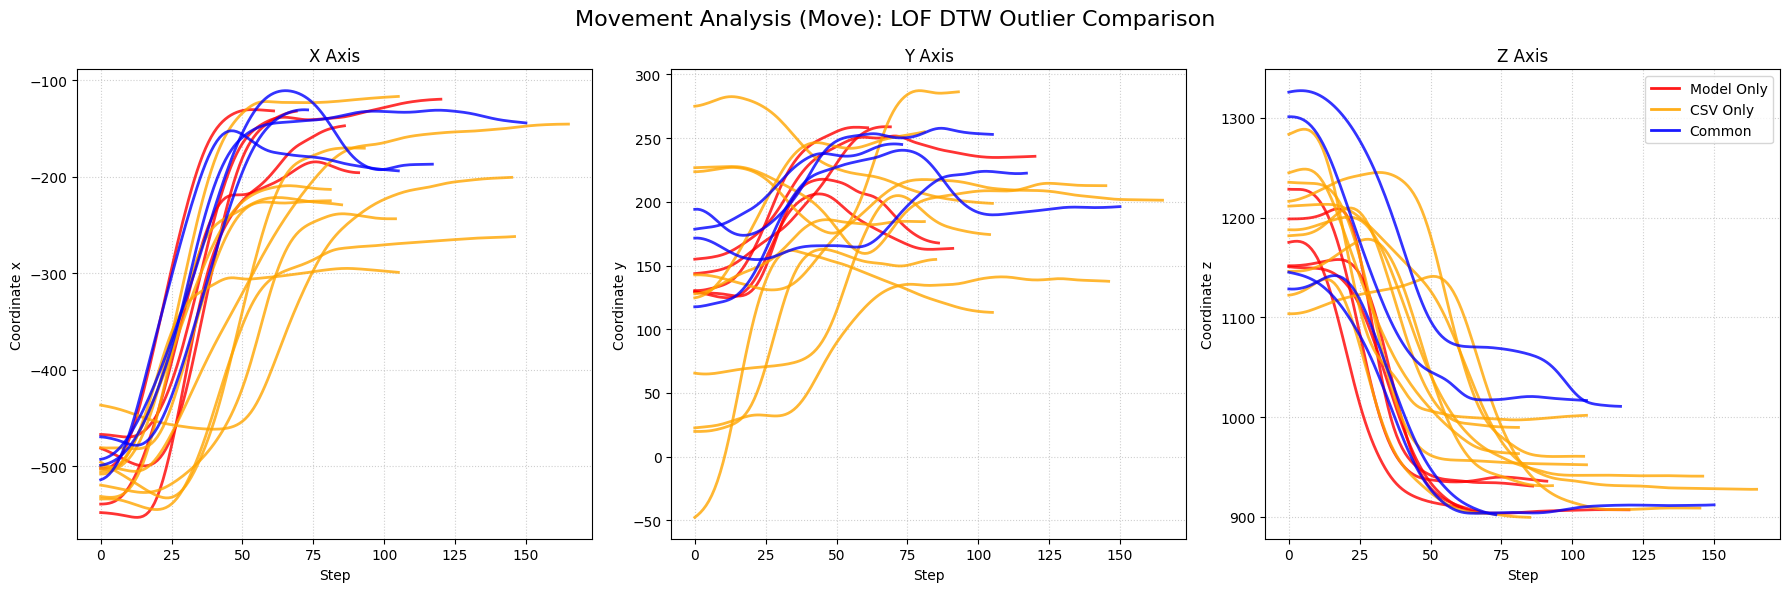

In [ ]:
plot_movement_analysis(
    X_movement=X_movement,
    full_metadata_df=full_metadata_df,
    model_metadata_df=lof_model_metadata_df,
    outliers_csv=outliers_csv,
    axis_names=['x', 'y', 'z'],
    model_name='LOF DTW',
    target_movement=TARGET_MOVEMENT
)

Common: 1 | Model-only: 2 | CSV-only: 13


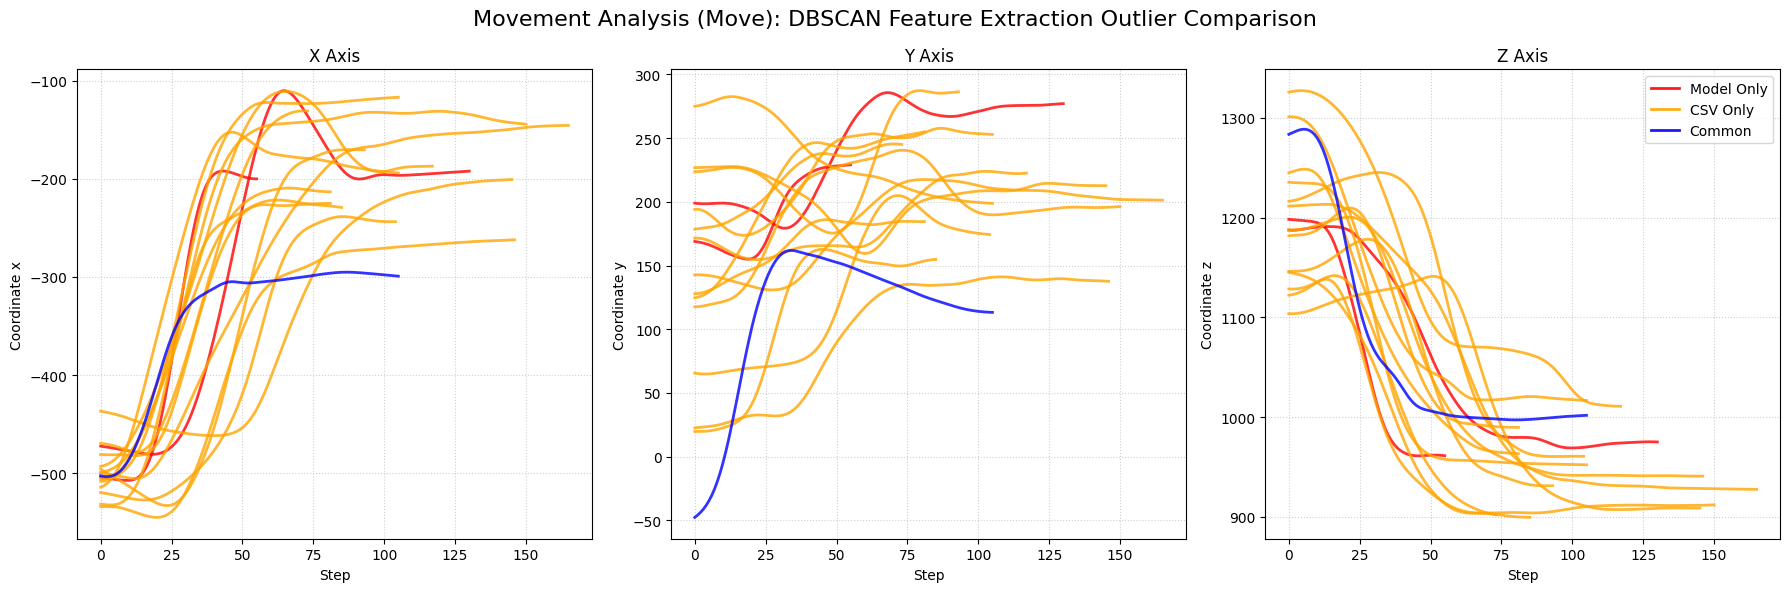

In [ ]:
plot_movement_analysis(
    X_movement=X_movement,
    full_metadata_df=full_metadata_df,
    model_metadata_df=dbscan_model_metadata_df,
    outliers_csv=outliers_csv,
    axis_names=['x', 'y', 'z'],
    model_name='DBSCAN Feature Extraction',
    target_movement=TARGET_MOVEMENT
)

---

In [ ]:
TARGET_MOVEMENT = "Move"

def normalize_everything(df, lof_outlier_data_df, dbscan_outliers_df, common_outliers_df, target_movement=TARGET_MOVEMENT):
        filtered_dbscan_outliers_df = dbscan_outliers_df[dbscan_outliers_df['movLabel'] == target_movement]
        filtered_lof_outlier_data_df = lof_outlier_data_df[lof_outlier_data_df['movLabel'] == target_movement]
        filtered_common_outliers_df = common_outliers_df[common_outliers_df['movLabel'] == target_movement]
        
        # Initialize variables to None to avoid UnboundLocalError when dataframes are empty
        X_lof_outliers = None
        X_dbscan_outliers = None

        X_movement = normalize_series(
                df_input=df,
                movLabel_filter=target_movement,
                useScaler=False,
                group_array=['x', 'y', 'z'],
                sample_size=None
        )  # shape (n_samples, T, n_features)

        if filtered_lof_outlier_data_df is not None and filtered_lof_outlier_data_df.size > 0:
                X_lof_outliers = normalize_series(
                        df_input=filtered_lof_outlier_data_df,
                        movLabel_filter=target_movement,
                        useScaler=False,
                        group_array=['x', 'y', 'z'],
                        sample_size=None
                )  # shape (n_samples, T, n_features)

        if filtered_dbscan_outliers_df is not None and filtered_dbscan_outliers_df.size > 0:
                X_dbscan_outliers = normalize_series(
                        df_input=filtered_dbscan_outliers_df,
                        movLabel_filter=target_movement,
                        useScaler=False,
                        group_array=['x', 'y', 'z'],
                        sample_size=None
                )  # shape (n_samples, T, n_features)

        X_common_outliers = normalize_series(
                df_input=filtered_common_outliers_df,
                movLabel_filter=target_movement,
                useScaler=False,
                group_array=['x', 'y', 'z'],
                sample_size=None
        )  # shape (n_samples, T, n_features)

        return X_movement, X_lof_outliers, X_dbscan_outliers, X_common_outliers


Poderia ter usado a função genérica que fiz, mas como isto vai ser bastante diferente, por respeito à minha futura pessoa que vai ter de inevitávelmente alterar aquilo, vou fazer uma função diferente desta vez. 

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

axis_names = ['x', 'y', 'z']

def plot_movement_analysis(
        axis_names,
        X_movement,
        X_lof_outliers,
        X_dbscan_outliers,
        X_common_outliers,
        target_movement=TARGET_MOVEMENT
    ):
    fig, axs = plt.subplots(1, len(axis_names), figsize=(18, 6))

    # Define legend
    legend_elements = [
        Line2D([0], [0], color='gray', lw=2, alpha=0.6, label='Clean'),
        Line2D([0], [0], color='red', lw=2, alpha=0.9, label='LOF Outliers'),
        Line2D([0], [0], color='orange', lw=2, alpha=0.9, label='DBSCAN Outliers'),
        Line2D([0], [0], color='blue', lw=2, alpha=0.6, label='Common Outliers')
    ]

    # Add other data to legend if provided
    for i, axis in enumerate(axis_names):
        ax = axs[i]

        # This came from the DTW models, which are numpy arrays of shape (n_samples, T, n_features)
        # for series in X_movement:
        #     ax.plot(series[:, i], color='gray', alpha=0.3)
        if X_lof_outliers is not None and len(X_lof_outliers) > 0:
            for series in X_lof_outliers:
                ax.plot(series[:, i], color='red', alpha=0.8, linewidth=2)
        
        if X_dbscan_outliers is not None and len(X_dbscan_outliers) > 0: # Se tudo for comum então estes plots não vão aparecer
            for series in X_dbscan_outliers:
                ax.plot(series[:, i], color='orange', alpha=0.8, linewidth=2)

        for series in X_common_outliers: # Se não houver nada nos dois de cima, neste obrigatóriamente tem de ter
            ax.plot(series[:, i], color='blue', alpha=0.6, linewidth=2)


        # Configure subplot
        ax.set_title(f'{axis.capitalize()} Axis ')
        ax.set_xlabel('Step')
        ax.set_ylabel(f'Coordinate {axis}')
        ax.grid(True, linestyle=':', alpha=0.6)

        # Add legend to the last plot
        if i == len(axis_names) - 1:
            ax.legend(handles=legend_elements, loc='upper right')

    # General title
    plt.suptitle(f'Movement Analysis ({target_movement}): Outlier Comparison', fontsize=16)
    plt.tight_layout()
    plt.show()


Processing time series: 100%|██████████| 380/380 [00:00<00:00, 6751.57it/s]


Shape of first series: (111, 3)
Shape of formatted series: (380, 241, 3)


Processing time series: 100%|██████████| 14/14 [00:00<00:00, 3345.69it/s]


Shape of first series: (111, 3)
Shape of formatted series: (14, 186, 3)


Processing time series: 100%|██████████| 3/3 [00:00<00:00, 1986.57it/s]


Shape of first series: (161, 3)
Shape of formatted series: (3, 161, 3)


Processing time series: 100%|██████████| 10/10 [00:00<00:00, 4177.59it/s]

Shape of first series: (116, 3)
Shape of formatted series: (10, 241, 3)


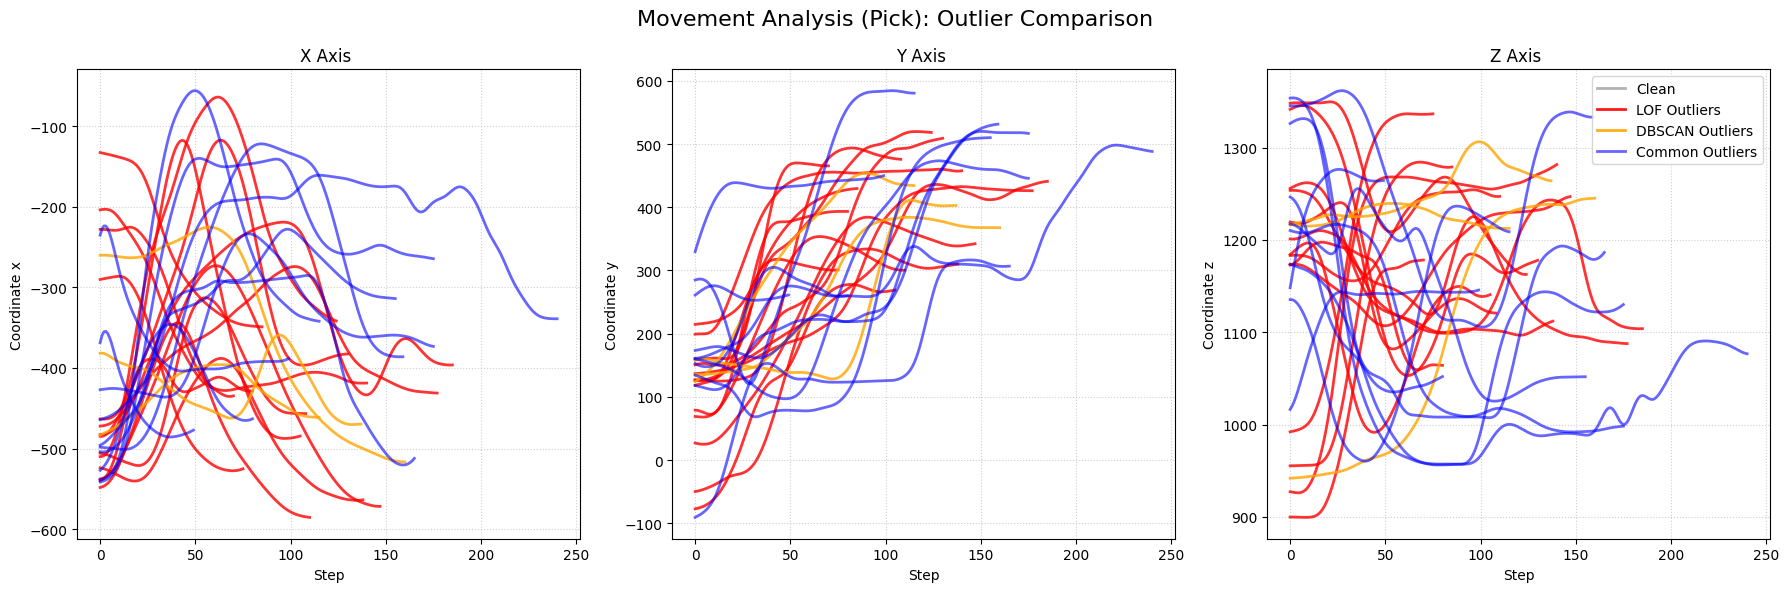

In [ ]:
X_movement, X_lof_outliers, X_dbscan_outliers, X_common_outliers = normalize_everything(df, lof_outlier_data_df, dbscan_outliers_df, common_outliers_df, target_movement="Pick")
plot_movement_analysis(axis_names, X_movement, X_lof_outliers, X_dbscan_outliers, X_common_outliers, target_movement="Pick")

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 6420.85it/s]


Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


Processing time series: 100%|██████████| 9/9 [00:00<00:00, 4466.25it/s]


Shape of first series: (108, 3)
Shape of formatted series: (9, 118, 3)


Processing time series: 100%|██████████| 3/3 [00:00<00:00, 2303.30it/s]


Shape of first series: (106, 3)
Shape of formatted series: (3, 106, 3)


Processing time series: 100%|██████████| 4/4 [00:00<00:00, 2486.99it/s]


Shape of first series: (162, 3)
Shape of formatted series: (4, 196, 3)


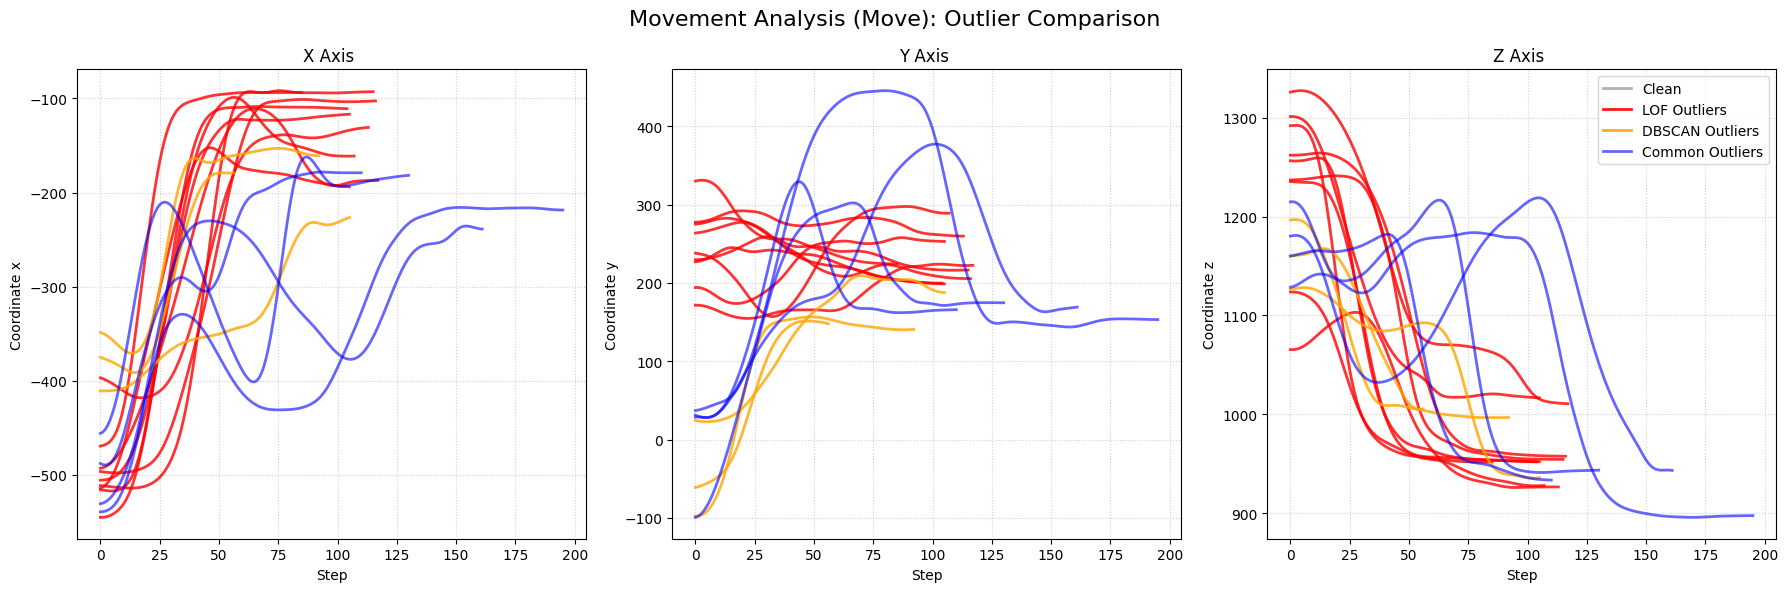

In [ ]:
X_movement, X_lof_outliers, X_dbscan_outliers, X_common_outliers = normalize_everything(df, lof_outlier_data_df, dbscan_outliers_df, common_outliers_df, "Move")
plot_movement_analysis(axis_names, X_movement, X_lof_outliers, X_dbscan_outliers, X_common_outliers, target_movement="Move")

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 6945.97it/s]


Shape of first series: (290, 3)
Shape of formatted series: (380, 290, 3)


Processing time series: 100%|██████████| 13/13 [00:00<00:00, 5567.28it/s]


Shape of first series: (144, 3)
Shape of formatted series: (13, 144, 3)


Processing time series: 100%|██████████| 20/20 [00:00<00:00, 5630.69it/s]


Shape of first series: (290, 3)
Shape of formatted series: (20, 290, 3)


Processing time series: 100%|██████████| 4/4 [00:00<00:00, 3281.93it/s]

Shape of first series: (90, 3)
Shape of formatted series: (4, 186, 3)


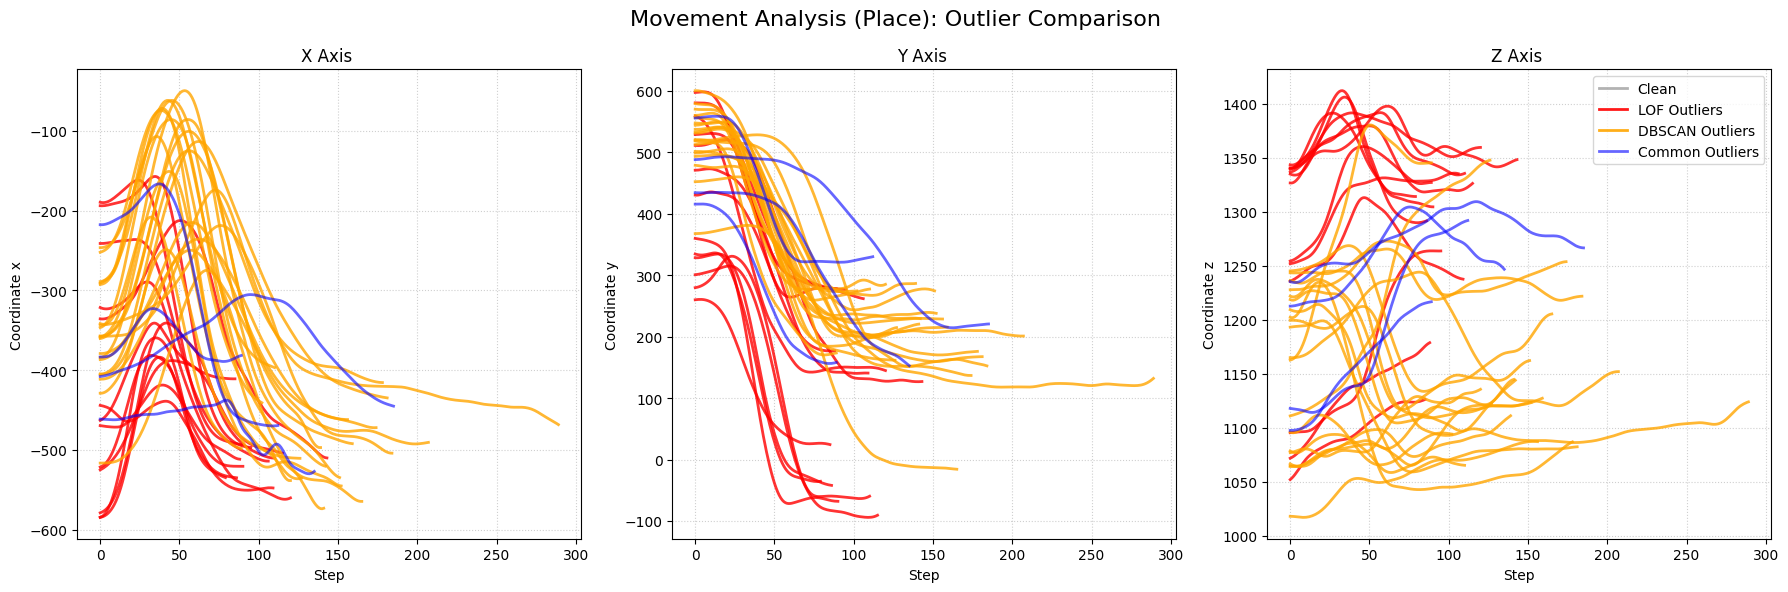

In [ ]:
X_movement, X_lof_outliers, X_dbscan_outliers, X_common_outliers = normalize_everything(df, lof_outlier_data_df, dbscan_outliers_df, common_outliers_df, target_movement="Place")
plot_movement_analysis(axis_names, X_movement, X_lof_outliers, X_dbscan_outliers, X_common_outliers, target_movement="Place")